<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FFishing-Zone-Prediction/notebooks/C2_fishing_zone_prediction/C2_1_download_and_build_datacube.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C2 – Notebook 1: Download data and build the datacube

**Run this notebook ONCE.** It downloads the ocean data and fishing-effort labels for the Sri Lanka area,
cuts them to a 0.25° grid, and saves ONE small datacube (~300 MB) to your Google Drive.

* Everything downloads on Google's servers, so it uses almost no mobile data.
* It is **resumable**: each half-year chunk is saved to Drive as soon as it finishes. If Colab disconnects,
  just run all cells again and it skips the parts that are already done.
* Expected time: 1–4 hours (mostly waiting for Copernicus servers). Keep the tab open.

**Before you start you need:**
1. Your Copernicus Marine username and password (marine.copernicus.eu)
2. A Global Fishing Watch API token (see Step 6)

Then: `Runtime → Run all`. You do NOT need a GPU for this notebook.

## Step 1 – Connect Google Drive and create folders

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE   = '/content/drive/MyDrive/C2_data'
CHUNKS = f'{BASE}/chunks'          # small per-half-year files (lets the download resume)
os.makedirs(CHUNKS, exist_ok=True)
print('Saving to:', BASE)

Mounted at /content/drive
Saving to: /content/drive/MyDrive/C2_data


## Step 2 – Install the Copernicus Marine toolbox

In [ ]:
!pip install -q copernicusmarine

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.8/135.8 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 85.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 54.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 7.8 MB/s eta 0:00:00


## Step 3 – Settings
Study area = Sri Lanka EEZ plus a margin. Grid = 0.25° (40 × 44 cells). Period = 2017–2024.

In [ ]:
import numpy as np, pandas as pd, xarray as xr, time, glob, warnings
warnings.filterwarnings('ignore')

LON_MIN, LON_MAX = 76.0, 87.0
LAT_MIN, LAT_MAX = 3.0, 13.0
RES = 0.25
LAT = np.arange(LAT_MIN + RES/2, LAT_MAX, RES)   # cell centres, 40 values
LON = np.arange(LON_MIN + RES/2, LON_MAX, RES)   # cell centres, 44 values

START, END = '2017-01-01', '2024-12-31'

# Half-year chunks (small enough to download reliably)
CHUNK_LIST = []
for y in range(int(START[:4]), int(END[:4]) + 1):
    CHUNK_LIST += [(f'{y}-01-01', f'{y}-06-30'), (f'{y}-07-01', f'{y}-12-31')]
print(len(LAT), 'x', len(LON), 'grid,', len(CHUNK_LIST), 'chunks')

40 x 44 grid, 16 chunks


## Step 4 – Log in to Copernicus Marine

In [ ]:
import copernicusmarine
from getpass import getpass
cm_user = input('Copernicus username: ')
cm_pass = getpass('Copernicus password: ')
copernicusmarine.login(username=cm_user, password=cm_pass, force_overwrite=True)

Copernicus username: kulanigayathree
Copernicus password: ··········


INFO - 2026-10-12T17:12:32Z - Credentials file stored in /root/.copernicusmarine/.copernicusmarine-credentials.
INFO:copernicusmarine:Credentials file stored in /root/.copernicusmarine/.copernicusmarine-credentials.


True

## Step 5 – Helper functions
`open_first` tries each dataset ID in order (reprocessed archive first, then the newer "interim"/near-real-time
version), because the long archives stop at a certain date. `to_grid` averages the fine data onto our 0.25° grid.

In [ ]:
def open_first(dataset_ids, variables, start=None, end=None, depth=None):
    # Stream a subset straight from Copernicus (no big raw file), trying each dataset ID in turn.
    last_err = None
    for ds_id in dataset_ids:
        kw = dict(dataset_id=ds_id, variables=variables,
                  minimum_longitude=LON_MIN - 0.5, maximum_longitude=LON_MAX + 0.5,
                  minimum_latitude=LAT_MIN - 0.5,  maximum_latitude=LAT_MAX + 0.5)
        if start: kw.update(start_datetime=start, end_datetime=end)
        if depth: kw.update(minimum_depth=depth[0], maximum_depth=depth[1])
        try:
            ds = copernicusmarine.open_dataset(**kw)
            if 'time' in ds.dims and ds.sizes['time'] == 0:
                raise ValueError('no time steps in range')
            return ds, ds_id
        except Exception as e:
            last_err = e
            print(f'   {ds_id} did not work for {start}..{end}: {str(e)[:120]}')
    raise RuntimeError(f'All dataset IDs failed: {last_err}')

def to_grid(da):
    # Average fine-resolution data onto the common 0.25° grid.
    da = da.sortby('latitude').sortby('longitude')
    res = float(abs(da.longitude[1] - da.longitude[0]))
    f = max(1, int(round(RES / res)))
    if f > 1:
        da = da.coarsen(latitude=f, longitude=f, boundary='trim').mean()
    return da.interp(latitude=LAT, longitude=LON)

def daily(ds):
    ds = ds.assign_coords(time=ds['time'].dt.floor('D'))
    return ds

def done(path):
    return os.path.exists(path) and os.path.getsize(path) > 1000

## Step 6a – Static data: sea-floor depth and land mask
From the GLORYS reanalysis static file. Land cells become NaN and are ignored later.

INFO - 2026-10-12T17:12:35Z - Selected dataset version: "202311"
INFO:copernicusmarine:Selected dataset version: "202311"
INFO - 2026-10-12T17:12:35Z - Selected dataset part: "bathy"
INFO:copernicusmarine:Selected dataset part: "bathy"


Ocean cells: 1421 of 1760


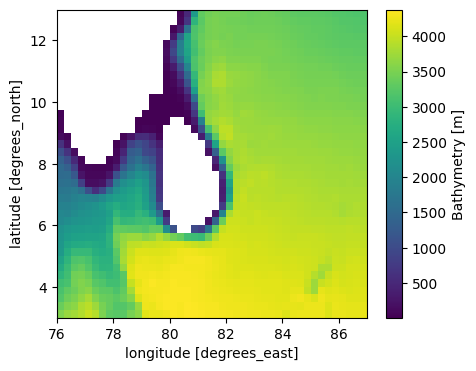

In [ ]:
STATIC = f'{BASE}/static_0p25.nc'
if not done(STATIC):
    st, _ = open_first(['cmems_mod_glo_phy_my_0.083deg_static'], ['deptho'])
    depth = to_grid(st['deptho'].load())
    xr.Dataset({'depth': depth.astype('float32')}).to_netcdf(STATIC)
static = xr.open_dataset(STATIC)
ocean = static['depth'].notnull()
print('Ocean cells:', int(ocean.sum()), 'of', ocean.size)
static['depth'].plot(figsize=(5,4));

## Step 6b – Ocean physics (GLORYS reanalysis)
One product gives: surface temperature (`thetao` → SST), currents (`uo`, `vo`), mixed-layer depth (`mlotst`)
and sea-surface height (`zos`, later turned into sea-level anomaly). ~10–20 min per chunk.

In [ ]:
PHY_IDS = ['cmems_mod_glo_phy_my_0.083deg_P1D-m',      # reprocessed archive (to mid-2021)
           'cmems_mod_glo_phy_myint_0.083deg_P1D-m']   # interim (mid-2021 onwards)

for s, e in CHUNK_LIST:
    out = f'{CHUNKS}/phy_{s[:7]}.nc'
    if done(out):
        print('skip', out); continue
    t0 = time.time(); print('downloading physics', s, '->', e)
    ds, used = open_first(PHY_IDS, ['thetao', 'uo', 'vo', 'mlotst', 'zos'], s, e, depth=(0, 1))
    ds = daily(ds)
    if 'depth' in ds.dims:
        ds = ds.isel(depth=0)
    ds = ds.load()
    g = xr.Dataset({
        'sst': to_grid(ds['thetao']), 'u': to_grid(ds['uo']), 'v': to_grid(ds['vo']),
        'mld': to_grid(ds['mlotst']), 'zos': to_grid(ds['zos'])}).astype('float32')
    g.attrs['source'] = used
    g.to_netcdf(out)
    print(f'   saved {out}  ({time.time()-t0:.0f}s, from {used})')

downloading physics 2017-01-01 -> 2017-06-30


INFO - 2026-10-12T17:12:44Z - Selected dataset version: "202311"
INFO:copernicusmarine:Selected dataset version: "202311"
INFO - 2026-10-12T17:12:44Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-12T17:12:44Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


   saved /content/drive/MyDrive/C2_data/chunks/phy_2017-01.nc  (43s, from cmems_mod_glo_phy_my_0.083deg_P1D-m)
downloading physics 2017-07-01 -> 2017-12-31


INFO - 2026-10-12T17:13:27Z - Selected dataset version: "202311"
INFO:copernicusmarine:Selected dataset version: "202311"
INFO - 2026-10-12T17:13:27Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-12T17:13:27Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


   saved /content/drive/MyDrive/C2_data/chunks/phy_2017-07.nc  (41s, from cmems_mod_glo_phy_my_0.083deg_P1D-m)
downloading physics 2018-01-01 -> 2018-06-30


...

   saved /content/drive/MyDrive/C2_data/chunks/phy_2023-07.nc  (41s, from cmems_mod_glo_phy_my_0.083deg_P1D-m)
downloading physics 2024-01-01 -> 2024-06-30


INFO - 2026-10-12T17:23:05Z - Selected dataset version: "202311"
INFO:copernicusmarine:Selected dataset version: "202311"
INFO - 2026-10-12T17:23:05Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-12T17:23:05Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


   saved /content/drive/MyDrive/C2_data/chunks/phy_2024-01.nc  (41s, from cmems_mod_glo_phy_my_0.083deg_P1D-m)
downloading physics 2024-07-01 -> 2024-12-31


INFO - 2026-10-12T17:23:46Z - Selected dataset version: "202311"
INFO:copernicusmarine:Selected dataset version: "202311"
INFO - 2026-10-12T17:23:46Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-12T17:23:46Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


   saved /content/drive/MyDrive/C2_data/chunks/phy_2024-07.nc  (39s, from cmems_mod_glo_phy_my_0.083deg_P1D-m)


## Step 6c – Chlorophyll-a (satellite ocean colour, gap-free daily 4 km)

In [ ]:
CHL_IDS = ['cmems_obs-oc_glo_bgc-plankton_my_l4-gapfree-multi-4km_P1D',
           'cmems_obs-oc_glo_bgc-plankton_myint_l4-gapfree-multi-4km_P1D',
           'cmems_obs-oc_glo_bgc-plankton_nrt_l4-gapfree-multi-4km_P1D']

for s, e in CHUNK_LIST:
    out = f'{CHUNKS}/chl_{s[:7]}.nc'
    if done(out):
        print('skip', out); continue
    t0 = time.time(); print('downloading chlorophyll', s, '->', e)
    ds, used = open_first(CHL_IDS, ['CHL'], s, e)
    ds = daily(ds).load()
    g = xr.Dataset({'chl': to_grid(ds['CHL'])}).astype('float32')
    g.attrs['source'] = used
    g.to_netcdf(out)
    print(f'   saved {out}  ({time.time()-t0:.0f}s, from {used})')

downloading chlorophyll 2017-01-01 -> 2017-06-30


INFO - 2026-10-12T17:24:25Z - Selected dataset version: "202603"
INFO:copernicusmarine:Selected dataset version: "202603"
INFO - 2026-10-12T17:24:25Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-12T17:24:25Z - You are using the dataset cmems_obs-oc_glo_bgc-plankton_my_l4-gapfree-multi-4km_P1D, version '202603', part 'default'. This exact version and part of the dataset will be retired on the 2026-11-24T13:00:00.000Z. For more information you can check: https://marine.copernicus.eu/user-corner/product-roadmap/transition-information


   saved /content/drive/MyDrive/C2_data/chunks/chl_2017-01.nc  (33s, from cmems_obs-oc_glo_bgc-plankton_my_l4-gapfree-multi-4km_P1D)
downloading chlorophyll 2017-07-01 -> 2017-12-31


INFO - 2026-10-12T17:24:58Z - Selected dataset version: "202603"
INFO:copernicusmarine:Selected dataset version: "202603"
INFO - 2026-10-12T17:24:58Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-12T17:24:58Z - You are using the dataset cmems_obs-oc_glo_bgc-plankton_my_l4-gapfree-multi-4km_P1D, version '202603', part 'default'. This exact version and part of the dataset will be retired on the 2026-11-24T13:00:00.000Z. For more information you can check: https://marine.copernicus.eu/user-corner/product-roadmap/transition-information


   saved /content/drive/MyDrive/C2_data/chunks/chl_2017-07.nc  (31s, from cmems_obs-oc_glo_bgc-plankton_my_l4-gapfree-multi-4km_P1D)
downloading chlorophyll 2018-01-01 -> 2018-06-30


...

   saved /content/drive/MyDrive/C2_data/chunks/chl_2023-07.nc  (42s, from cmems_obs-oc_glo_bgc-plankton_my_l4-gapfree-multi-4km_P1D)
downloading chlorophyll 2024-01-01 -> 2024-06-30


INFO - 2026-10-12T17:32:05Z - Selected dataset version: "202603"
INFO:copernicusmarine:Selected dataset version: "202603"
INFO - 2026-10-12T17:32:05Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-12T17:32:05Z - You are using the dataset cmems_obs-oc_glo_bgc-plankton_my_l4-gapfree-multi-4km_P1D, version '202603', part 'default'. This exact version and part of the dataset will be retired on the 2026-11-24T13:00:00.000Z. For more information you can check: https://marine.copernicus.eu/user-corner/product-roadmap/transition-information


   saved /content/drive/MyDrive/C2_data/chunks/chl_2024-01.nc  (32s, from cmems_obs-oc_glo_bgc-plankton_my_l4-gapfree-multi-4km_P1D)
downloading chlorophyll 2024-07-01 -> 2024-12-31


INFO - 2026-10-12T17:32:37Z - Selected dataset version: "202603"
INFO:copernicusmarine:Selected dataset version: "202603"
INFO - 2026-10-12T17:32:37Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-12T17:32:37Z - You are using the dataset cmems_obs-oc_glo_bgc-plankton_my_l4-gapfree-multi-4km_P1D, version '202603', part 'default'. This exact version and part of the dataset will be retired on the 2026-11-24T13:00:00.000Z. For more information you can check: https://marine.copernicus.eu/user-corner/product-roadmap/transition-information


   saved /content/drive/MyDrive/C2_data/chunks/chl_2024-07.nc  (31s, from cmems_obs-oc_glo_bgc-plankton_my_l4-gapfree-multi-4km_P1D)


## Step 7 – Fishing-effort labels from Global Fishing Watch (API)

**Get a token (one time):** go to https://globalfishingwatch.org/our-apis/tokens , sign in (free account),
create a token (purpose: *academic research*), and copy it. Paste it below when asked.

The API returns apparent fishing hours on a 0.1° daily grid. We request one month at a time
(the API allows one report at a time) and save each month, so this part is resumable too.

In [ ]:
import requests, zipfile, io, json
GFW_TOKEN = getpass('Paste your Global Fishing Watch API token: ')
GFW_URL = 'https://gateway.api.globalfishingwatch.org/v3/4wings/report'
HEAD = {'Authorization': f'Bearer {GFW_TOKEN}', 'Content-Type': 'application/json'}
POLY = {'type': 'Polygon', 'coordinates': [[[LON_MIN, LAT_MIN], [LON_MAX, LAT_MIN],
         [LON_MAX, LAT_MAX], [LON_MIN, LAT_MAX], [LON_MIN, LAT_MIN]]]}
GFW_DIR = f'{CHUNKS}/gfw'; os.makedirs(GFW_DIR, exist_ok=True)
BODY_STYLE = 'object'

def _records(obj):
    # Walk any JSON structure and collect dicts that look like grid rows.
    if isinstance(obj, dict):
        if {'lat', 'lon', 'hours'} <= obj.keys():
            yield obj
        else:
            for v in obj.values(): yield from _records(v)
    elif isinstance(obj, list):
        for v in obj: yield from _records(v)

def _parse(content):
    if content[:2] == b'PK':                      # zip file
        z = zipfile.ZipFile(io.BytesIO(content))
        name = [n for n in z.namelist() if n.endswith('.json')][0]
        content = z.read(name)
    return pd.DataFrame(list(_records(json.loads(content))))

def gfw_month(start, end):
    params = {'spatial-resolution': 'LOW', 'temporal-resolution': 'DAILY', 'group-by': 'GEARTYPE',
              'datasets[0]': 'public-global-fishing-effort:latest', 'date-range': f'{start},{end}',
              'format': 'JSON'}
    global BODY_STYLE
    for attempt in range(8):
        body = {'geojson': POLY} if BODY_STYLE == 'object' else {'geojson': json.dumps(POLY)}
        r = requests.post(GFW_URL, params=params, headers=HEAD, json=body, timeout=300)
        if r.status_code == 200:
            return _parse(r.content)
        if r.status_code == 422 and BODY_STYLE == 'object':   # try the other polygon format once
            BODY_STYLE = 'string'; continue
        if r.status_code in (401, 403):
            raise RuntimeError('Token rejected - check the GFW token. ' + r.text[:200])
        if r.status_code == 524:                  # report took too long; fetch it when ready
            for _ in range(30):
                time.sleep(20)
                lr = requests.get(GFW_URL.replace('report', 'last-report'), headers=HEAD, timeout=300)
                if lr.status_code == 200 and lr.content[:2] == b'PK':
                    return _parse(lr.content)
        print(f'   GFW {r.status_code}: {r.text[:150]} - retrying'); time.sleep(30)
    raise RuntimeError(f'GFW failed for {start}..{end}')

months = pd.date_range(START, END, freq='MS')
for m in months:
    s, e = m.strftime('%Y-%m-%d'), (m + pd.offsets.MonthBegin(1)).strftime('%Y-%m-%d')
    out = f'{GFW_DIR}/gfw_{s[:7]}.csv'
    if os.path.exists(out): continue
    df = gfw_month(s, e)
    df.to_csv(out, index=False)
    print(s[:7], len(df), 'rows')
print('GFW done')

Paste your Global Fishing Watch API token: ··········
2017-01 57 rows
2017-02 175 rows
2017-03 48 rows
2017-04 50 rows
2017-05 61 rows
2017-06 113 rows
2017-07 140 rows
2017-08 133 rows
2017-09 125 rows
2017-10 61 rows
2017-11 143 rows
2017-12 77 rows
2018-01 93 rows
2018-02 115 rows
2018-03 388 rows
2018-04 274 rows
2018-05 399 rows
2018-06 360 rows
2018-07 528 rows
2018-08 647 rows
2018-09 429 rows
2018-10 669 rows
2018-11 523 rows
2018-12 392 rows
2019-01 408 rows
2019-02 365 rows
2019-03 650 rows
2019-04 547 rows
2019-05 640 rows
2019-06 407 rows
2019-07 521 rows
2019-08 628 rows
2019-09 498 rows
2019-10 483 rows
2019-11 499 rows
2019-12 615 rows
2020-01 887 rows
2020-02 1435 rows
2020-03 737 rows
2020-04 315 rows
2020-05 270 rows
2020-06 348 rows
2020-07 472 rows
2020-08 721 rows
2020-09 634 rows
2020-10 564 rows
2020-11 313 rows
2020-12 371 rows
2021-01 220 rows
2021-02 405 rows
2021-03 941 rows
2021-04 623 rows
2021-05 604 rows
2021-06 401 rows
2021-07 435 rows
2021-08 604 rows


## Step 8 – Build the datacube
Joins all chunks, adds derived features, and saves **one file** to Drive. After this, the `chunks`
folder can be deleted to free Drive space (keep it until you have checked the datacube).

| Channel | Meaning |
|---|---|
| sst, sst_grad | sea-surface temperature and its front strength |
| log_chl | log10 chlorophyll-a |
| sla | sea-level anomaly (zos minus its 2017–2021 mean) |
| u, v, cur_speed | surface currents |
| mld | mixed-layer depth |
| depth | sea-floor depth (static) |
| moon_sin, moon_cos | lunar phase |
| doy_sin, doy_cos | season (monsoon cycle) |

In [ ]:
def join(pattern):
    parts = [xr.open_dataset(f).load() for f in sorted(glob.glob(f'{CHUNKS}/{pattern}'))]
    ds = xr.concat(parts, dim='time')
    return ds.sel(time=~ds.get_index('time').duplicated())
phy = join('phy_*.nc'); chl = join('chl_*.nc')
# GLORYS chunks carry a leftover 'depth' (0.49 m) coordinate; drop it so it doesn't clash with sea-floor depth
phy = phy.drop_vars('depth', errors='ignore'); chl = chl.drop_vars('depth', errors='ignore')
days = pd.date_range(START, END, freq='D')
phy = phy.reindex(time=days); chl = chl.reindex(time=days)

# Derived ocean features
sst = phy['sst']
km_lat = 111.0; km_lon = 111.0 * np.cos(np.deg2rad(sst.latitude))
gy = sst.differentiate('latitude') / km_lat        # degC per km
gx = sst.differentiate('longitude') / km_lon
sst_grad = np.sqrt(gx**2 + gy**2)
sla = phy['zos'] - phy['zos'].sel(time=slice('2017', '2021')).mean('time')
log_chl = np.log10(chl['chl'].clip(min=1e-3))
cur_speed = np.sqrt(phy['u']**2 + phy['v']**2)

# Lunar phase (0 = new moon, 0.5 = full moon) from a standard synodic-month formula
jd = days.to_julian_date().values
phase = ((jd - 2451550.1) / 29.530588853) % 1.0
doy = days.dayofyear.values / 365.25
def bcast(vals):
    return xr.DataArray(np.broadcast_to(vals[:, None, None], (len(days), len(LAT), len(LON))).copy(),
                        coords={'time': days, 'latitude': LAT, 'longitude': LON}, dims=('time', 'latitude', 'longitude'))

# Sea-floor depth repeated for every day (Notebook 2 needs every feature to have a time dimension)
depth_t = static['depth'].drop_vars('depth', errors='ignore') \
    .assign_coords(latitude=sst.latitude, longitude=sst.longitude).broadcast_like(sst)

X = xr.Dataset({
    'sst': sst, 'sst_grad': sst_grad, 'log_chl': log_chl, 'sla': sla,
    'u': phy['u'], 'v': phy['v'], 'cur_speed': cur_speed, 'mld': phy['mld'],
    'depth': depth_t,
    'moon_sin': bcast(np.sin(2*np.pi*phase)), 'moon_cos': bcast(np.cos(2*np.pi*phase)),
    'doy_sin': bcast(np.sin(2*np.pi*doy)), 'doy_cos': bcast(np.cos(2*np.pi*doy)),
}).astype('float32')
X = X.where(ocean)            # land = NaN
print(X)

<xarray.Dataset> Size: 267MB
Dimensions:    (time: 2922, latitude: 40, longitude: 44)
Coordinates:
  * time       (time) datetime64[ns] 23kB 2017-01-01 2017-01-02 ... 2024-12-31
  * latitude   (latitude) float64 320B 3.125 3.375 3.625 ... 12.38 12.62 12.88
  * longitude  (longitude) float64 352B 76.12 76.38 76.62 ... 86.38 86.62 86.88
Data variables: (12/13)
    sst        (time, latitude, longitude) float32 21MB 28.15 28.16 ... 28.54
    sst_grad   (time, latitude, longitude) float32 21MB 0.001191 ... 0.003425
    log_chl    (time, latitude, longitude) float32 21MB -0.5781 ... -0.8419
    sla        (time, latitude, longitude) float32 21MB -0.1 -0.092 ... 0.08553
    u          (time, latitude, longitude) float32 21MB 0.04778 ... 0.001383
    v          (time, latitude, longitude) float32 21MB 0.2764 0.2007 ... 0.0167
    ...         ...
    mld        (time, latitude, longitude) float32 21MB 10.71 10.76 ... 38.02
    depth      (time, latitude, longitude) float32 21MB 3.557e+03 ... 3

In [ ]:
# Labels: grid GFW 0.1 deg fishing hours onto the 0.25 deg grid (sum per cell per day)
g = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f'{GFW_DIR}/gfw_*.csv'))], ignore_index=True)
g = g[(g.lat >= LAT_MIN) & (g.lat < LAT_MAX) & (g.lon >= LON_MIN) & (g.lon < LON_MAX)]
g['date'] = pd.to_datetime(g['date'].astype(str).str[:10])
g = g[(g.date >= START) & (g.date <= END)]
g['iy'] = ((g.lat - LAT_MIN) // RES).astype(int); g['ix'] = ((g.lon - LON_MIN) // RES).astype(int)
g['it'] = (g.date - pd.Timestamp(START)).dt.days
agg = g.groupby(['it', 'iy', 'ix'])['hours'].sum().reset_index()
hours = np.zeros((len(days), len(LAT), len(LON)), dtype='float32')
hours[agg.it.values, agg.iy.values, agg.ix.values] = agg.hours.values
hours = xr.DataArray(hours, coords=X.sst.coords, dims=X.sst.dims).where(ocean)
X['fishing_hours'] = hours
X['fishing'] = (hours > 0).astype('float32').where(ocean)

print('Share of ocean cell-days with fishing:', float(X.fishing.mean()))
CUBE = f'{BASE}/datacube_0p25.nc'
enc = {v: {'zlib': True, 'complevel': 4} for v in X.data_vars}
X.to_netcdf(CUBE, encoding=enc)
print('Saved', CUBE, f'{os.path.getsize(CUBE)/1e6:.0f} MB')

Share of ocean cell-days with fishing: 0.0468914732336998
Saved /content/drive/MyDrive/C2_data/datacube_0p25.nc 124 MB


## Step 9 – Quick check (small plots)

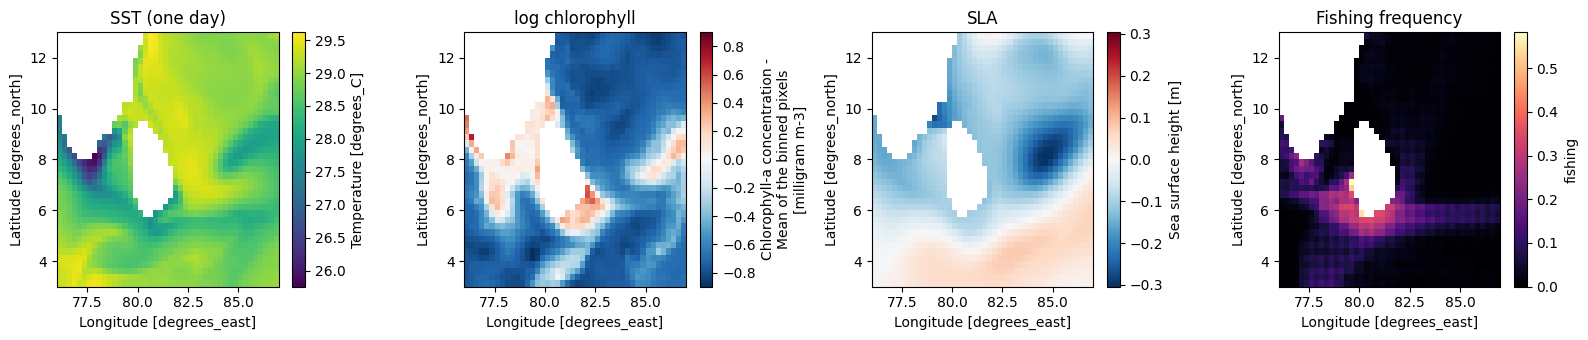

Missing values per variable (ocean cells):
{'sst': 0.0, 'log_chl': 0.02, 'sla': 0.0, 'mld': 0.0}


In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
X.sst.isel(time=200).plot(ax=ax[0]); ax[0].set_title('SST (one day)')
X.log_chl.isel(time=200).plot(ax=ax[1]); ax[1].set_title('log chlorophyll')
X.sla.isel(time=200).plot(ax=ax[2], cmap='RdBu_r'); ax[2].set_title('SLA')
X.fishing.mean('time').plot(ax=ax[3], cmap='magma'); ax[3].set_title('Fishing frequency')
plt.tight_layout(); plt.show()
print('Missing values per variable (ocean cells):')
print({v: round(float(X[v].isnull().where(ocean).mean()), 3) for v in ['sst', 'log_chl', 'sla', 'mld']})